# Layer H — estimation hygiene (shrinkage / winner's curse): a NULL result

We rank/gate on the EWMA funding estimate. Ranking many noisy estimates and taking the winners risks
the **winner's curse** (admitting names flattered by luck). Layer H shrinks each estimate toward the
cross-section (`μ_shr = ω·μ_est + (1−ω)·μ_cs`). We find: **the curse is real but it's a *level* bias
(forward funding ≈ 0.5× the estimate), not a *ranking* failure** — shrinkage de-biases the level but
leaves the cross-sectional ranking unchanged, so selection doesn't improve (and the backtest is
slightly worse). The θ_keep exit + funding vetoes already bound the damage. All via `lab.py`.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'
import sys; from pathlib import Path
_p = Path.cwd().resolve()
ROOT = next((q for q in [_p, *_p.parents] if (q/'pyproject.toml').exists()), _p)
sys.path[:0] = [str(ROOT)]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import research.funding_carry.lab as H
from src.common import config as cfg
plt.rcParams.update({'figure.figsize':(14,3.8),'axes.grid':True,'grid.alpha':0.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
NAVY,TEAL,AMBER,RED,GREY='#1f3a5f','#2a9d8f','#e0a32e','#c1121f','0.6'
COSTS=cfg.load_config('strategies/funding_carry/v3.1.yaml')['costs']
maj,non=H.universe(); P=H.load_panels(maj+non); F,E,didx,syms=P['F'],P['E'],P['didx'],P['symbols']
SIG=H.signal_apr(F,7).reindex(index=didx,columns=syms).where(E)                 # μ_est (point)
FWD=(F.rolling(30,min_periods=20).mean().shift(-30)*365).where(E)               # forward-30d realized funding APR
fvol=H.feature_panels(P,[{'name':'funding_vol','window':30}])['funding_vol']
Neff=20.0; mu_cs=SIG.mean(axis=1); s2=(fvol**2)/Neff
tau2=((SIG.sub(mu_cs,axis=0)**2).mean(axis=1)-s2.mean(axis=1)).clip(lower=1e-6)
omega=(s2.add(tau2,axis=0)).rdiv(tau2,axis=0).clip(0,1)                          # per-name empirical-Bayes ω
MU_EB=H.shrink(SIG,omega); MU_FIX=H.shrink(SIG,0.5); LCB=SIG-1.0*(fvol/np.sqrt(Neff))
print('avg EB ω', round(omega.stack().mean(),2), '| corr(ω, funding_vol)', round(omega.stack().corr(fvol.stack()),2))

avg EB ω 0.88 | corr(ω, funding_vol) -0.49


## 1. The winner's curse is real — but it's a level bias

Bin names by their point estimate and plot the mean **forward** funding per bin against the estimate.
Points sit **below the 45° line**: the estimate overstates (~2×, pooled slope 0.50), worst near the
entry gate. This is what shrinkage is meant to fix.

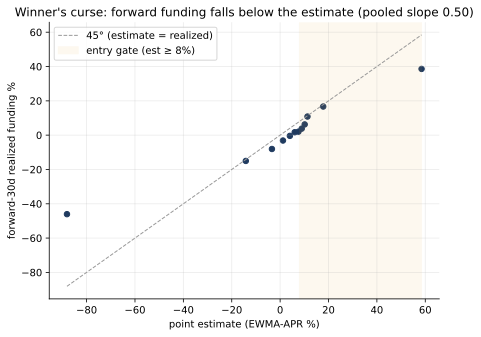

In [2]:
s=SIG.stack(); f=FWD.reindex_like(SIG).stack(); d=pd.concat([s.rename('e'),f.rename('y')],axis=1).dropna(); d=d[np.abs(d['e'])<5]
d['b']=pd.qcut(d['e'],12,labels=False,duplicates='drop'); g=d.groupby('b').agg(e=('e','mean'),y=('y','mean'))
slope=np.polyfit(d['e'],d['y'],1)[0]
fig,ax=plt.subplots(figsize=(7,5))
lim=[g['e'].min()*100,g['e'].max()*100]
ax.plot(lim,lim,color=GREY,ls='--',lw=1,label='45° (estimate = realized)')
ax.scatter(g['e']*100,g['y']*100,s=30,color=NAVY)
ax.axvspan(8,lim[1],color=AMBER,alpha=0.08,label='entry gate (est ≥ 8%)')
ax.set_xlabel('point estimate (EWMA-APR %)'); ax.set_ylabel('forward-30d realized funding %')
ax.legend(); ax.set_title(f'Winner\'s curse: forward funding falls below the estimate (pooled slope {slope:.2f})')
plt.show()

## 2. Shrinkage de-biases the *level* but does NOT re-rank

Shrinkage pulls the level toward the cross-section (slope → 1) and cuts RMSE a little — but the
**cross-sectional rank-IC is unchanged** (fixed-ω is a monotone within-day transform; even per-name
EB ω barely moves it). LCB (penalizing funding-vol) makes ranking *worse* — funding-vol carries real
carry, not just noise. Selection uses the *ranking*, so there's nothing to gain.

In [3]:
from scipy.stats import spearmanr
def stats(pred):
    dd=pd.concat([pred.stack().rename('p'),FWD.reindex_like(SIG).stack().rename('y')],axis=1).dropna(); dd=dd[np.abs(dd['p'])<5]
    slope=np.polyfit(dd['p'],dd['y'],1)[0]
    ics=[pred.loc[t].rank().corr(FWD.loc[t].rank()) for t in didx[::3] if (pred.loc[t].notna()&FWD.loc[t].notna()).sum()>=20]
    return slope, np.nanmean(ics), np.sqrt(((dd['y']-dd['p'])**2).mean())*100
tab={}
for n,e in [('μ_est (point)',SIG),('shr fixed ω=0.5',MU_FIX),('shr EB (per-name ω)',MU_EB),('LCB μ−1·se',LCB)]:
    sl,ic,rm=stats(e); tab[n]={'slope→1':round(sl,2),'rank-IC':round(ic,3),'RMSE%':round(rm,1)}
print(pd.DataFrame(tab).T.to_string())
print('\n→ slope improves (de-biased) but rank-IC is flat: shrinkage does not change WHICH names rank top.')

                     slope→1  rank-IC  RMSE%
μ_est (point)           0.50    0.516   48.1
shr fixed ω=0.5         0.72    0.516   44.8
shr EB (per-name ω)     0.79    0.515   45.2
LCB μ−1·se              0.39    0.496   52.3

→ slope improves (de-biased) but rank-IC is flat: shrinkage does not change WHICH names rank top.


## 3. Backtest — plugging μ_shr into selection does not help

Feed the EB-shrunk signal into the full v3.1 stack (veto + inverse-vol + band unchanged), matched to
v3.1's name count. Result: **slightly worse** on Sharpe, 2×-cost, and turnover — in-sample and OOS.

In [4]:
SPECS=[{'name':'funding_vol','window':30},{'name':'neg_freq','window':30},{'name':'basis','window':30}]
VETO=[{'feature':'funding_vol','direction':'max','cap':0.75},{'feature':'neg_freq','direction':'max','cap':0.40},{'feature':'basis','direction':'max','cap':0.01}]
feats=H.feature_panels(P,SPECS+[{'name':'basis_vol','window':30}]); invvol=1.0/feats['basis_vol'].replace(0.0,np.nan)
def run(sig,ti,tk,mask=None):
    vok=H.veto_mask(feats,VETO,sig)&feats['basis_vol'].notna()&(feats['basis_vol']>0)
    W=H.deadband_weights(H.weights_from_held(H.held_matrix(sig,vok,ti,tk,None,None),invvol),0.5)
    return H.book(W,P,COSTS,mask=mask,warmup_days=30),(H.held_matrix(sig,vok,ti,tk,None,None)>0).sum(axis=1).mean()
v31,n31=run(SIG,0.08,0.02)
best=min(((run(MU_EB,ti,ti/4),ti) for ti in (0.05,0.06,0.07,0.08,0.09,0.10)),key=lambda x:abs(x[0][1]-n31))
(v33,n33),ti33=best
def row(res,n):
    a,b=res['1.0x'],res['2.0x']; return {'Sharpe':a['sharpe'],'Sh@2x':b['sharpe'],'net%':round(a['ann_return']*100,1),'maxDD%':round(a['max_drawdown']*100,1),'turn':round(a['ann_turnover'],0),'names':round(n,0)}
print(pd.DataFrame({'v3.1 (point est)':row(v31,n31),f'v3.3 (EB shrink, θ={ti33})':row(v33,n33)}).T.to_string())
tr=H._window_mask(didx,end='2023-12-31'); te=H._window_mask(didx,start='2024-01-01')
print('\nOOS (train 21-23 -> TEST 24-26):')
for tag,sig,ti in [('v3.1',SIG,0.08),('v3.3 EB',MU_EB,ti33)]:
    a=run(sig,ti,ti/4,tr)[0]['1.0x']; b=run(sig,ti,ti/4,te)[0]
    print(f"  {tag:8} train Sh {a['sharpe']:.2f} | TEST Sh {b['1.0x']['sharpe']:.2f} 2x {b['2.0x']['sharpe']:.2f} net {b['1.0x']['ann_return']:+.1%} turn {b['1.0x']['ann_turnover']:.0f}x")

                          Sharpe  Sh@2x  net%  maxDD%  turn  names
v3.1 (point est)           6.316  3.624   9.9    -2.8  20.0  113.0
v3.3 (EB shrink, θ=0.08)   5.955  3.047   9.6    -3.3  22.0  110.0

OOS (train 21-23 -> TEST 24-26):


  v3.1     train Sh 6.25 | TEST Sh 7.52 2x 4.32 net +7.4% turn 14x


  v3.3 EB  train Sh 5.89 | TEST Sh 7.21 2x 3.80 net +7.1% turn 15x


## Conclusion — Layer H not shipped

- **The winner's curse is real** (forward funding ≈ 0.5× the point estimate; names admitted at est ≥
  8% realize ~6pp less) — but it's a **level bias, not a ranking failure**.
- **Shrinkage de-biases the level** (slope 0.5 → ~0.7–0.9) with slightly lower RMSE, but **rank-IC is
  unchanged** — it does not change which names rank top, so selection (a ranking + threshold) gains
  nothing; matched-count backtests are slightly *worse* in-sample and OOS. LCB is worse still.
- **Why it doesn't bite:** the EWMA is already a per-name denoiser (EB ω ≈ 0.88 — only ~12% shrink
  warranted); the level bias only matters for the absolute θ, which v1 already validated; and the
  **θ_keep exit + funding-instability veto already drop the reverting false-entries**, so preventing
  the entry adds no net value.
- **Decision:** keep **v3.1**. `lab.shrink` kept as a reusable primitive. Pattern across G & H: v3.1's
  vetoes + hysteresis + inverse-vol already capture the exploitable structure; the remaining doc layers
  target risks/biases handled upstream or that don't affect the selection ranking. **Next lever is
  execution/capacity realism, not more signal/sizing sophistication.**